In [ ]:
# ── Librerías ─────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import janitor
import sqlalchemy as sa
import os
from pathlib import Path
from dotenv import load_dotenv

%matplotlib inline

# ── Opciones de visualización ─────────────────────────────────────────
# Desactivar notación científica
pd.set_option('display.float_format', '{:.3f}'.format)
np.set_printoptions(suppress=True)

# Ver todas las columnas al imprimir un DataFrame
pd.set_option('display.max_columns', None)

# ── Rutas del proyecto ────────────────────────────────────────────────
# Se resuelven desde la ubicación del notebook, así funcionan
# igual en cualquier máquina
RAIZ = Path.cwd().parent

ORIGINALES   = RAIZ / '02_datos' / '01_Originales'
VALIDACION   = RAIZ / '02_datos' / '02_Validacion'
ENTRENAMIENTO = RAIZ / '02_datos' / '03_Entrenamiento'
CACHES       = RAIZ / '02_datos' / '04_Caches'
MODELOS      = RAIZ / '05_modelos'
RESULTADOS   = RAIZ / '06_resultados'

# ── Variables de entorno ──────────────────────────────────────────────
load_dotenv(RAIZ / '.env')

print('✅ Entorno listo')
print(f'   Raíz del proyecto: {RAIZ}')

✅ Entorno listo
   Raíz del proyecto: c:\Users\Admin\Desktop\Desktop\CarpetaFisica\Data Detective\Mis Casos(Importante)\PROYECTO 5 - FORECASTING RETAIL\02_FORECASTING


In [2]:
#traemos la informacion de conexion desde la db
con = sa.create_engine('sqlite:///../02_datos/01_Originales/hipermercado.db')

from sqlalchemy import inspect
inspector = inspect(con)
tablas = inspector.get_table_names()
tablas


['calendar', 'sales', 'sell_prices']

In [21]:
cal = pd.read_sql('calendar', con) #instanciar un DataFrame
cal.drop(columns='index', inplace=True)
cal.rename(columns={'d': 'dia_ind'}, inplace=True)
cal.head(10)

,date,wm_yr_wk,weekday,wday,month,year,dia_ind,event_name_1,event_type_1,event_name_2,event_type_2
0,2013-01-01,11249,Tuesday,4,1,2013,d_704,NewYear,National,NaN,NaN
1,2013-01-02,11249,Wednesday,5,1,2013,d_705,NaN,NaN,NaN,NaN
2,2013-01-03,11249,Thursday,6,1,2013,d_706,NaN,NaN,NaN,NaN
3,2013-01-04,11249,Friday,7,1,2013,d_707,NaN,NaN,NaN,NaN
4,2013-01-05,11250,Saturday,1,1,2013,d_708,NaN,NaN,NaN,NaN
5,2013-01-06,11250,Sunday,2,1,2013,d_709,NaN,NaN,NaN,NaN
6,2013-01-07,11250,Monday,3,1,2013,d_710,OrthodoxChristmas,Religious,NaN,NaN
7,2013-01-08,11250,Tuesday,4,1,2013,d_711,NaN,NaN,NaN,NaN
8,2013-01-09,11250,Wednesday,5,1,2013,d_712,NaN,NaN,NaN,NaN
9,2013-01-10,11250,Thursday,6,1,2013,d_713,NaN,NaN,NaN,NaN


In [12]:
sales = pd.read_sql('sales', con) #instanciar un DataFrame
sales.drop(columns='index', inplace=True)
sales.head(10)

id      item_id  dept_id cat_id store_id state_id  \
0  FOODS_3_090_CA_3_validation  FOODS_3_090  FOODS_3  FOODS     CA_3       CA   
1  FOODS_3_120_CA_3_validation  FOODS_3_120  FOODS_3  FOODS     CA_3       CA   
2  FOODS_3_202_CA_3_validation  FOODS_3_202  FOODS_3  FOODS     CA_3       CA   
3  FOODS_3_252_CA_3_validation  FOODS_3_252  FOODS_3  FOODS     CA_3       CA   
4  FOODS_3_288_CA_3_validation  FOODS_3_288  FOODS_3  FOODS     CA_3       CA   
5  FOODS_3_329_CA_3_validation  FOODS_3_329  FOODS_3  FOODS     CA_3       CA   
6  FOODS_3_555_CA_3_validation  FOODS_3_555  FOODS_3  FOODS     CA_3       CA   
7  FOODS_3_586_CA_3_validation  FOODS_3_586  FOODS_3  FOODS     CA_3       CA   
8  FOODS_3_587_CA_3_validation  FOODS_3_587  FOODS_3  FOODS     CA_3       CA   
9  FOODS_3_714_CA_3_validation  FOODS_3_714  FOODS_3  FOODS     CA_3       CA   

   d_704  d_705  d_706  d_707  d_708  d_709  d_710  d_711  d_712  d_713  \
0      0    224    241    232    301    270    188    215    197    245   
1      0      0      0      0      0      0      0      0      0      0   
2     20     23     23     25     28     29     28     26     24     25   
3     34     27     40     49     34     28     22     23     11     19   
4      0      0      0      0      0      0      0      0      0      0   
5     39     75     54     46     63     66     63     55     45     50   
6      9     31     37     24     34     34     24     26     24     19   
7     50     62     65     76     84     82     67     57     42     56   
8     23     24     19     17    105    114     64     23     25     11   
9     17     16     24     26     21     21     16     19     18     12   

   d_714  d_715  d_716  d_717  d_718  d_719  d_720  d_721  d_722  d_723  \
0    214    351    281    206    158    191    170    224    362    255   
1      0      0      0      0      0      0      0      0      0      0   
2     16     35     30     24     14     11     11     19     16     25   
3     28     36     31     23     21     17     12     23     29     31   
4      0      0      0      0      0      0      0      0      0      0   
5     37     70     72     58     48     64     47     42     56     82   
6     19     35     31     22     26     22     18     35     33     38   
7     69     67     86     41     44     46     53     53     79     81   
8     58     95     95     66     31     44     22     41     49     41   
9     19     18     24      7     21     18     21     18     23     23   

   d_724  d_725  d_726  d_727  d_728  d_729  d_730  d_731  d_732  d_733  \
0    237     63      0      0      0    208    208    127    148    109   
1      0      0      0      0      0      0      0      0      0      0   
2     22     18     15     19     18     26     34     31     19     18   
3     19     40     13     29     30     23     22     19     25     13   
4      0      0      0      0      0      0      0      0      0      0   
5     59     41     62     58     46     63     89     51     55     45   
6     36     29      9     20     21     32     32     15     22     19   
7     71     71     48     54     72     65     65     49     47     44   
8      1     36     46     30     38     51     78     62     36     33   
9     22     23     13     17     23     16     23     13     11     18   

   d_734  d_735  d_736  d_737  d_738  d_739  d_740  d_741  d_742  d_743  \
0    136    257    268    300    118     88     93    148    188    167   
1      0      0      0      0      0      0      0      0      0      0   
2      8     28     37     43     29     25     28     17     32     27   
3     28     28     38     23     20     26     17     21     18     31   
4      0      0      0      0      0      0      0      0     38     47   
5     26     45     70     84     76     73     30     40     45     81   
6     22     31     33     38     26     18     21     21     32     43   
7     51     64     80     83     56     64     61     67 

In [13]:
# vamos a meltear el DataFrame de ventas
sales = sales.melt(id_vars=['id', 'item_id', 'dept_id', 'cat_id',
                                   'store_id','state_id']
                          , var_name='dia_ind', value_name='ventas')
sales.drop(columns='id', inplace=True)
sales.head(10)

,item_id,dept_id,cat_id,store_id,state_id,dia_ind,ventas
0,FOODS_3_090,FOODS_3,FOODS,CA_3,CA,d_704,0
1,FOODS_3_120,FOODS_3,FOODS,CA_3,CA,d_704,0
2,FOODS_3_202,FOODS_3,FOODS,CA_3,CA,d_704,20
3,FOODS_3_252,FOODS_3,FOODS,CA_3,CA,d_704,34
4,FOODS_3_288,FOODS_3,FOODS,CA_3,CA,d_704,0
5,FOODS_3_329,FOODS_3,FOODS,CA_3,CA,d_704,39
6,FOODS_3_555,FOODS_3,FOODS,CA_3,CA,d_704,9
7,FOODS_3_586,FOODS_3,FOODS,CA_3,CA,d_704,50
8,FOODS_3_587,FOODS_3,FOODS,CA_3,CA,d_704,23
9,FOODS_3_714,FOODS_3,FOODS,CA_3,CA,d_704,17


In [14]:
#miraremos precios de la tabla sell_prices dentro del objeto prices

prices = pd.read_sql('sell_prices', con) #instanciar un DataFrame
prices.drop(columns='index', inplace=True)
prices.head(10)

,store_id,item_id,wm_yr_wk,sell_price
0,CA_3,FOODS_3_090,11249,1.250
1,CA_3,FOODS_3_090,11250,1.250
2,CA_3,FOODS_3_090,11251,1.250
3,CA_3,FOODS_3_090,11252,1.250
4,CA_3,FOODS_3_090,11301,1.380
5,CA_3,FOODS_3_090,11302,1.380
6,CA_3,FOODS_3_090,11303,1.380
7,CA_3,FOODS_3_090,11304,1.380
8,CA_3,FOODS_3_090,11305,1.380
9,CA_3,FOODS_3_090,11306,1.380


# CREAR EL TABLON ANALITICO

Entender la relacion entre las diferentes tablas y cómo se conectan para construir el tablon analitico.

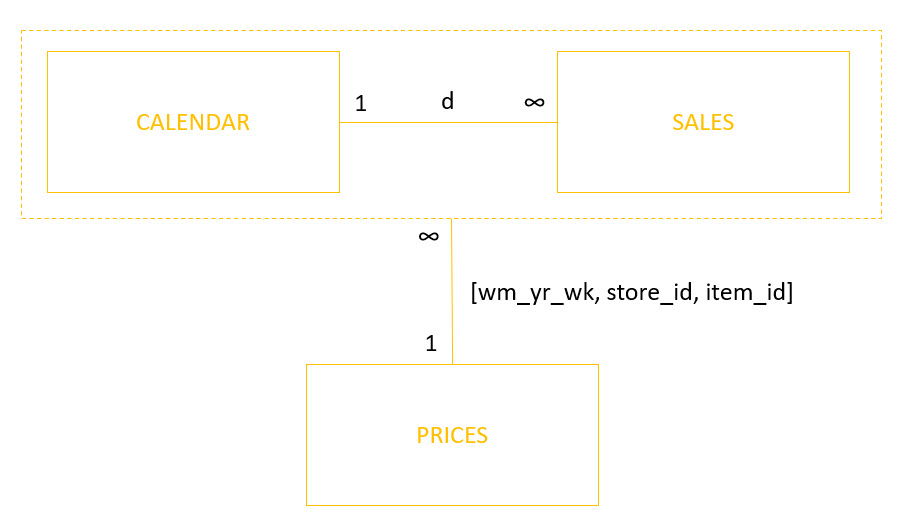

In [18]:
from IPython.display import Image

Image('../01_Documentos/CasoRetail_EstructuraRelaciones.jpg')

## Hacemos join

In [22]:
# Hacemos los Joins correspondientes entre las ventas y el calendario y despues price
# la principal fue sales porque contiene la info de las ventas que queremos analizar y predecir.
df = sales.merge(right = cal, on='dia_ind', how='left')
df = df.merge(right = prices, on=['store_id', 'item_id','wm_yr_wk'], how='left')

In [23]:
# Reordenar columnas y poner fecha como indice, vamos de mas a menos,
# desde state_id, store_id, dept_id, cat_id, item_id, 'wm_yr_wk', dia_ind,
#  ventas, sell_price, 'year','month','wday','weekday',y los eventos

orden = ['date', 'state_id', 'store_id', 'dept_id', 'cat_id', 'item_id', 'wm_yr_wk', 'dia_ind',
         'ventas', 'sell_price', 'year', 'month', 'wday', 'weekday',
           'event_name_1','event_type_1', 'event_name_2', 'event_type_2']

df = df[orden].set_index('date')

Extraemos y reservamos el dataset de validacion , pero OJO que es forecasting,
es decir, debemos tomar las últimas observaciones del tiempo para validación.

Tomamos desde 2015-12-01 a 2015-12-31 para nuestro conjunto de validación.

In [24]:
val = df.loc['2015-12-01':'2015-12-31']
val.to_pickle("../02_datos/02_Validacion/validacion.pkl")

In [27]:
train = df[:'2015-11-30']
train.to_pickle("../02_datos/03_Entrenamiento//train.pkl")